In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE

import matplotlib.pyplot as plt

# Load your dataset
data = pd.read_csv('2yr.txt', delimiter=',')
#data1 = pd.read_excel('Michael_Model_RUN-6-7.xlsx', sheet_name='2Lines-fake_Training_data')
#data = data.append(data1)
data['TM_STAMP'] = (pd.to_datetime(data['TM_STAMP']).astype('int64') // 10**9)

data=data.dropna()


In [2]:
data

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,REPORTABLE
0,0,392,1609459200,8679.682617,3.000000,True
1,1,392,1609462800,8679.713867,3.000000,True
2,2,392,1609466400,8679.676758,3.000000,True
3,3,392,1609470000,8679.657227,3.000000,True
4,4,392,1609473600,8679.676758,3.000000,True
...,...,...,...,...,...,...
22345305,22345305,2932,1669928400,8218.050781,3.068180,True
22345306,22345306,2931,1669924800,7904.056152,3.350971,True
22345307,22345307,2931,1669928400,7904.080566,3.351511,True
22345308,22345308,2930,1669924800,8579.653320,3.453717,True


In [3]:
# Preprocess the data
X = data[['ID_PIEZO','DIGITS','AMP']]
y = data['REPORTABLE']
X, y = shuffle(X, y, random_state=42)
X

,ID_PIEZO,DIGITS,AMP
3258,1154,8398.241211,2.375000
18513614,959,8536.234375,2.875000
10105564,1899,7275.482910,3.187500
17264043,273,8795.477539,3.062500
1899113,278,8124.690430,3.000000
...,...,...,...
10406576,2560,8915.950195,3.020279
15713153,977,8058.395020,2.750000
2415538,1978,9016.266602,2.187500
14353273,1181,8666.260742,2.125000


In [4]:
# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [5]:
X_train = X[:int(0.7*20745236 )]
#X_val = X[int(0.5*20745236):int(0.70*20745236)]
X_test = X[int(0.70*20745236):]

y_train = y[:int(0.7*20745236)]
#y_val = y[int(0.5*20745236):int(0.70*20745236)]
y_test = y[int(0.70*20745236):]

In [6]:
def get_model():
    model = keras.Sequential([
         layers.Dense(256, activation="tanh"),
         layers.Dense(256, activation="tanh"),
         layers.Dense(1, activation="sigmoid")
    ])
    #opt = keras.optimizers.Adam(learning_rate=0.002)
    #sgd=keras.optimizers.SGD(lr=0.01)
    model.compile(optimizer='adam',
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

model = get_model()
history_noise = model.fit(
    X_train, y_train,
    epochs = 10,
    batch_size=512,
    validation_data = (X_test, y_test))


Epoch 1/10
28363/28363 [==============================] - 232s 8ms/step - loss: 0.0213 - accuracy: 0.9947 - val_loss: 0.0134 - val_accuracy: 0.9972
Epoch 2/10
28363/28363 [==============================] - 222s 8ms/step - loss: 0.0102 - accuracy: 0.9974 - val_loss: 0.0076 - val_accuracy: 0.9981
Epoch 3/10
28363/28363 [==============================] - 215s 8ms/step - loss: 0.0077 - accuracy: 0.9979 - val_loss: 0.0069 - val_accuracy: 0.9983
Epoch 4/10
28363/28363 [==============================] - 198s 7ms/step - loss: 0.0067 - accuracy: 0.9983 - val_loss: 0.0064 - val_accuracy: 0.9981
Epoch 5/10
28363/28363 [==============================] - 240s 8ms/step - loss: 0.0061 - accuracy: 0.9983 - val_loss: 0.0057 - val_accuracy: 0.9984
Epoch 6/10
28363/28363 [==============================] - 198s 7ms/step - loss: 0.0058 - accuracy: 0.9984 - val_loss: 0.0060 - val_accuracy: 0.9982
Epoch 7/10
28363/28363 [==============================] - 196s 7ms/step - loss: 0.0057 - accuracy: 0.9984 - val_

In [7]:
history_dict = history_noise.history
history_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

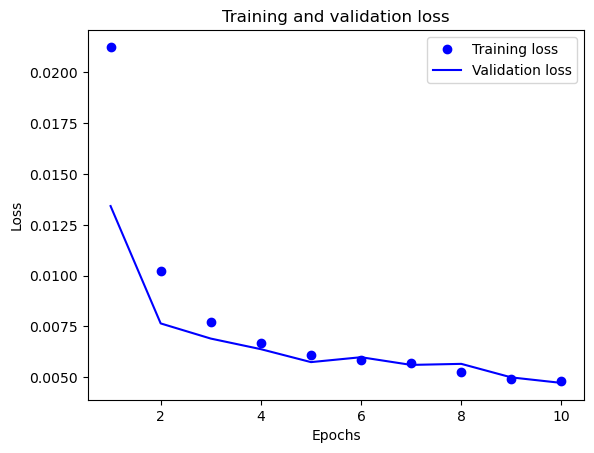

In [8]:
history_dict = history_noise.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

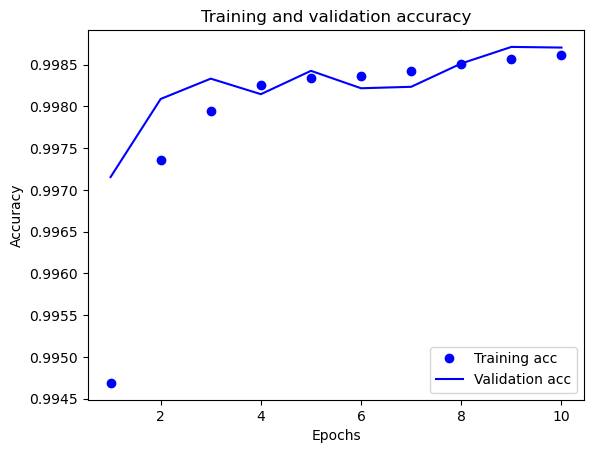

In [9]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
#pred = model.predict(X_test)

In [ ]:
for i in range(len(pred)):
    if pred[i] >= 0.5:
        pred[i] = 1
    else:
        pred[i] = 0

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [10]:
val = pd.read_csv('Q1_2023 (1).txt', delimiter=',')
val['TM_STAMP'] = (pd.to_datetime(val['TM_STAMP']).astype('int64') // 10**9)
val=val.dropna()

In [11]:
val_y1 = val['REPORTABLE'].astype('float')
val_x1 = val[['ID_PIEZO','DIGITS','AMP']]

val_x1 = scaler.transform(val_x1)

In [12]:
pred_val = model.evaluate(val_x1, val_y1)

71232/71232 [==============================] - 143s 2ms/step - loss: 0.0234 - accuracy: 0.9961


In [14]:
pre_val= model.predict(val_x1)
pre_val

71232/71232 [==============================] - 119s 2ms/step


array([[0.9997984 ],
       [0.99978715],
       [0.99978304],
       ...,
       [0.9999927 ],
       [0.9999927 ],
       [0.9999927 ]], dtype=float32)

In [15]:
for i in range(len(pre_val)):
    if pre_val[i] >= 0.5:
        pre_val[i] = 1
    else:
        pre_val[i] = 0

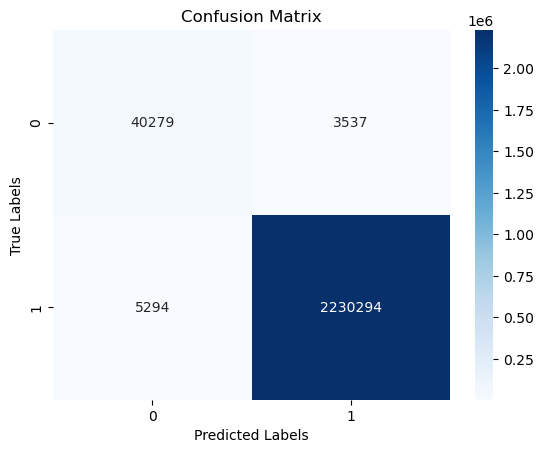

In [17]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(val_y1, pre_val)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [18]:
# Add the predictions to the new dataset
val['PREDICTIONS'] = pre_val

val['TM_STAMP'] = pd.to_datetime(val['TM_STAMP'], unit='s')
val

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,REPORTABLE,PREDICTIONS
0,0,287,2023-01-01 18:00:00,8535.119141,0.0625,True,1.0
1,1,287,2023-01-01 23:00:00,8534.709961,0.0625,True,1.0
2,2,287,2023-01-02 00:00:00,8534.567383,0.0625,True,1.0
3,3,287,2023-01-02 01:00:00,8534.438477,0.0625,True,1.0
4,4,287,2023-01-02 02:00:00,8534.282227,0.0625,True,1.0
...,...,...,...,...,...,...,...
2428397,2428397,1182,2023-01-11 02:00:00,8937.125977,2.3125,True,1.0
2428400,2428400,1182,2023-01-12 03:00:00,8937.468750,2.3125,True,1.0
2428402,2428402,1182,2023-01-12 14:00:00,8937.841797,2.3125,True,1.0
2428403,2428403,1182,2023-01-12 16:00:00,8937.884766,2.3125,True,1.0


In [19]:
val['REPORTABLE'] =val['REPORTABLE'].astype('float')

In [20]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Assuming you already have the new_data dataframe
# Step 2: Create a new column to store the comparison results
val['COMPARE'] = val['REPORTABLE'] == (val['PREDICTIONS'] == 1)

# Get unique ID_PIEZO values for predicted false and actual REPORTABLE false
predicted_false = val.loc[val['PREDICTIONS'] == 0, 'ID_PIEZO'].unique()
actual_reportable_false = val.loc[val['REPORTABLE'] == False, 'ID_PIEZO'].unique()

# Save the unique ID_PIEZO's for predicted false and actual REPORTABLE false in separate text files
with open("PIEZO_Predicted_False.txt", 'w') as f:
    for id_piezo in predicted_false:
        f.write(str(id_piezo) + '\n')

with open("Actual_Piezo_Reportable_False.txt", 'w') as f:
    for id_piezo in actual_reportable_false:
        f.write(str(id_piezo) + '\n')

# Step 4: Create a confusion matrix
y_true = val['REPORTABLE']
y_pred = val['PREDICTIONS'].apply(lambda x: x == 1)  # Convert 1's and 0's to boolean values
cm = confusion_matrix(y_true, y_pred)

# Create a labeled confusion matrix using a Pandas DataFrame
labeled_cm = pd.DataFrame(cm, index=['Actual: False', 'Actual: True'], columns=['Predicted: False', 'Predicted: True'])

print("Confusion Matrix:")
print(labeled_cm)

Confusion Matrix:
               Predicted: False  Predicted: True
Actual: False             40279             3537
Actual: True               5294          2230294


In [21]:
# importing os module
# Directory
import shutil
import os
directory = "ML_FIGURES"

 

dir ="C:/Temp/ML_FIGURES_check7"
if os.path.exists(dir):
    shutil.rmtree(dir)
os.makedirs(dir)

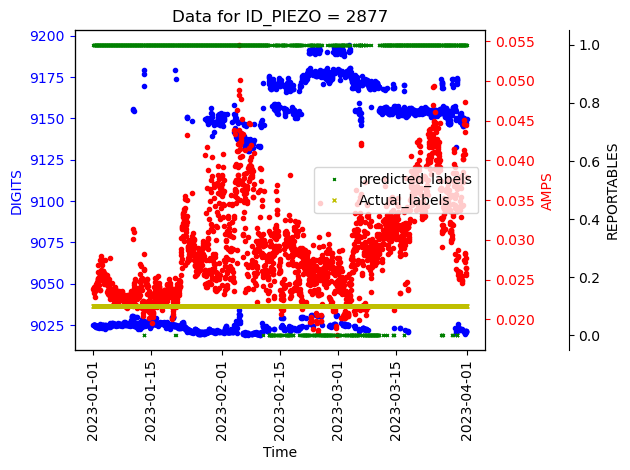

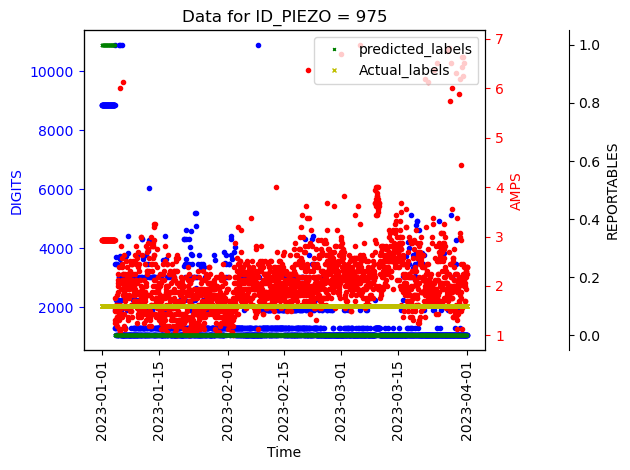

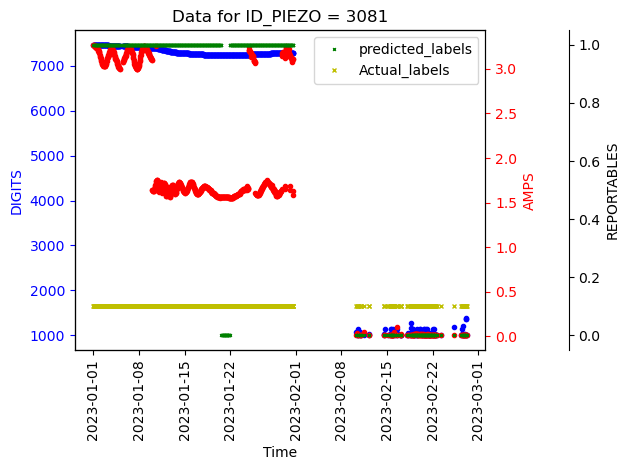

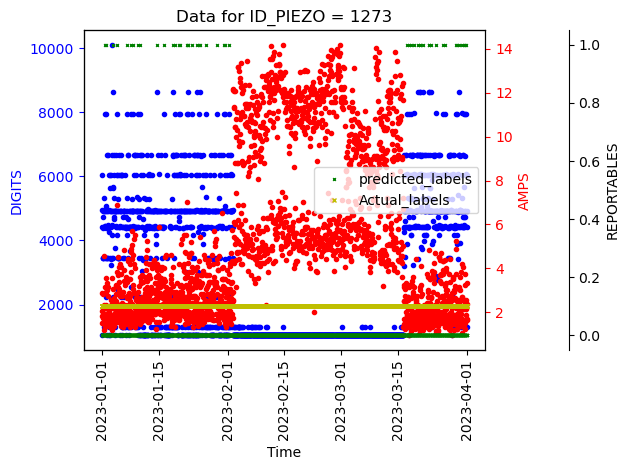

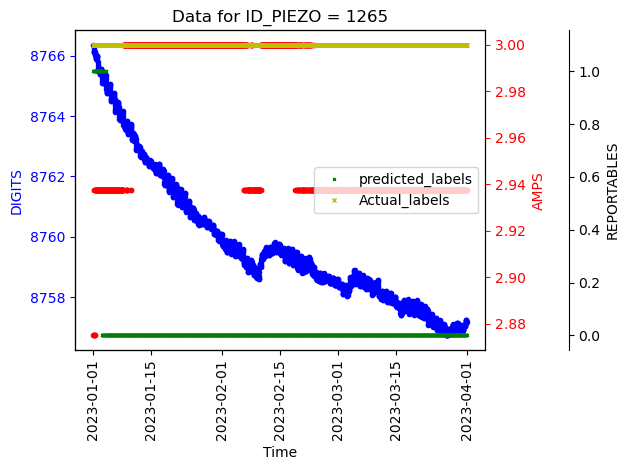

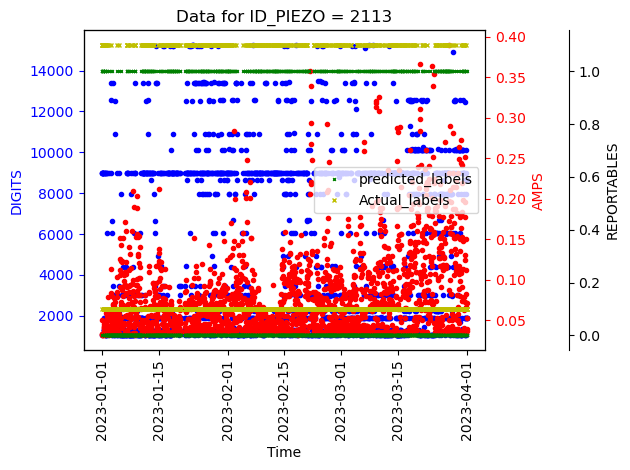

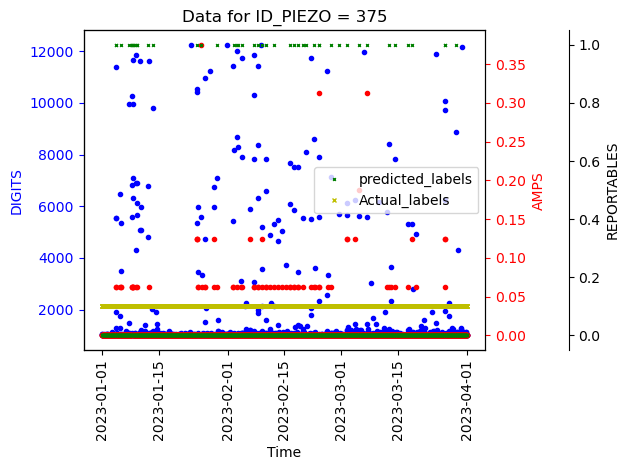

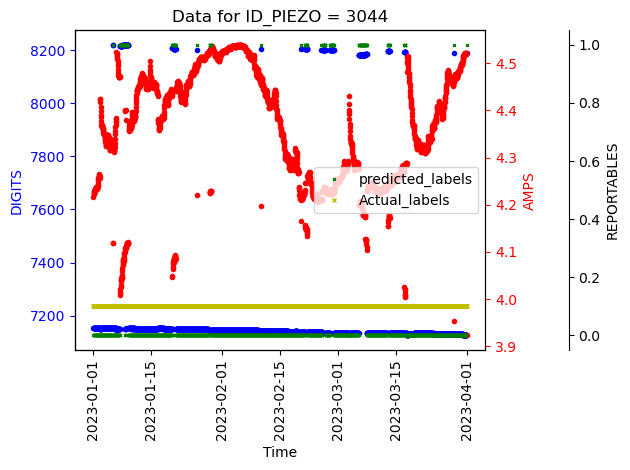

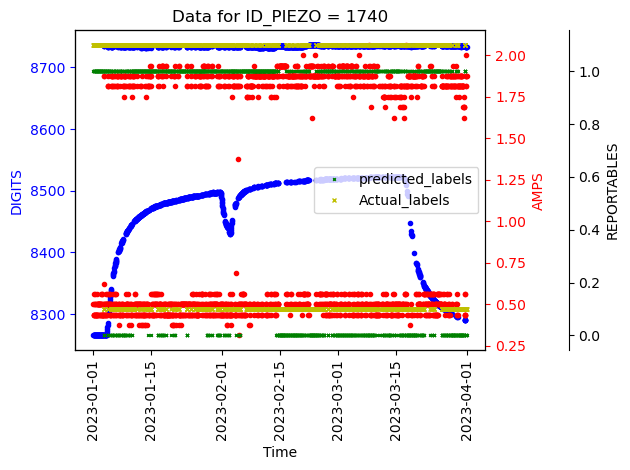

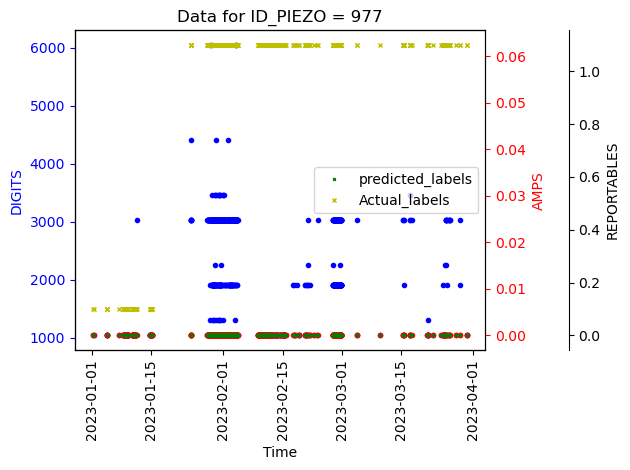

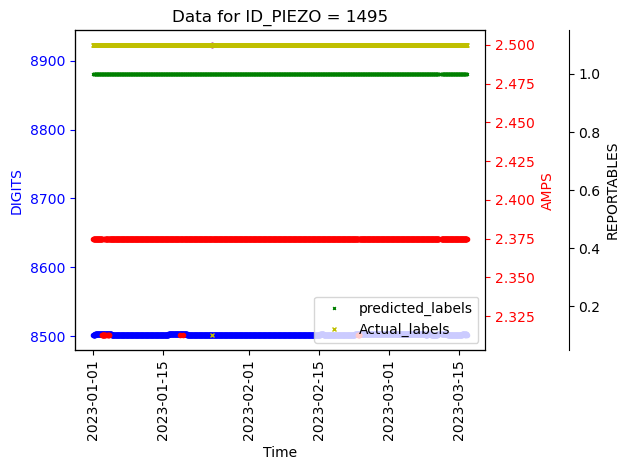

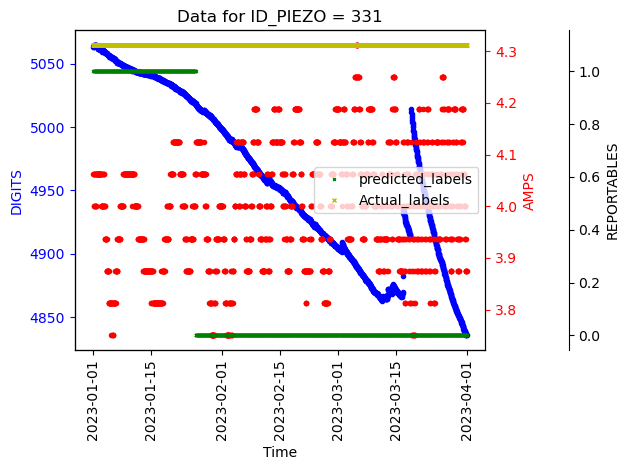

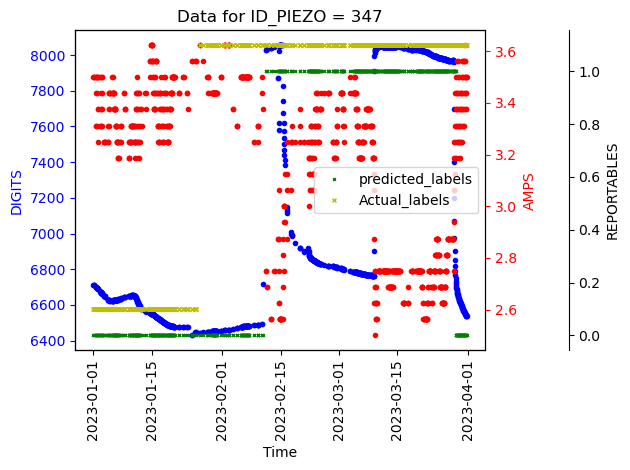

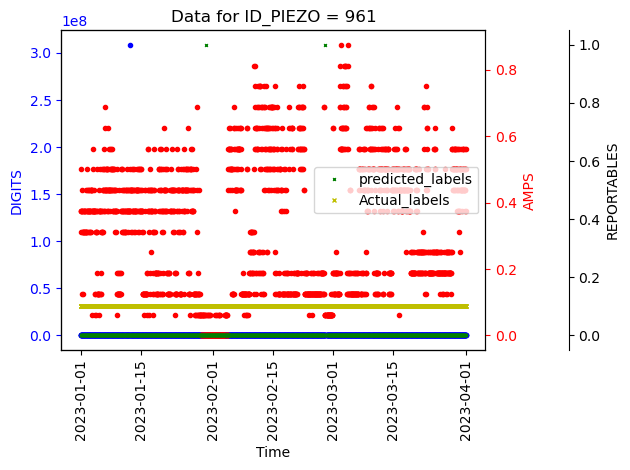

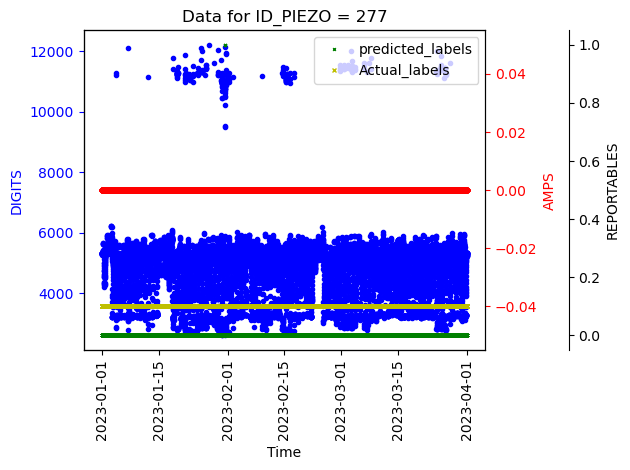

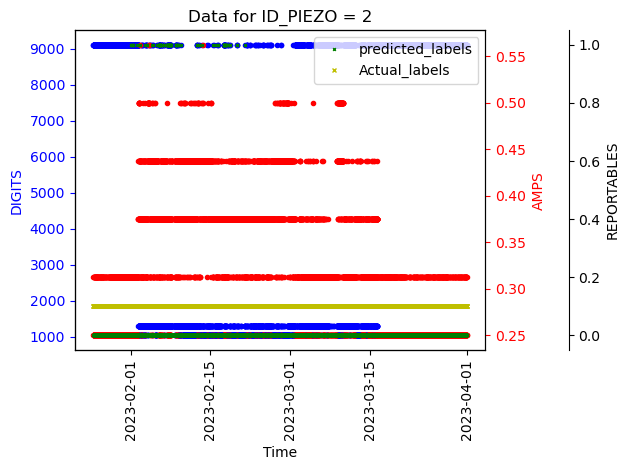

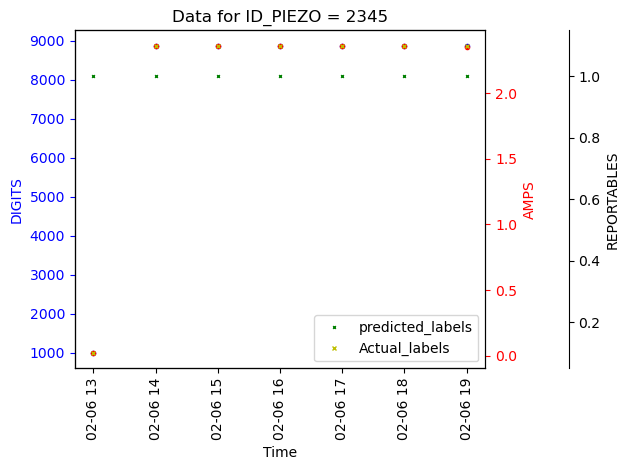

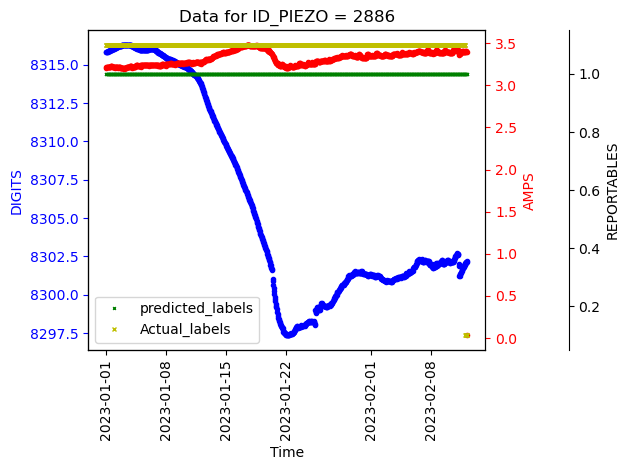

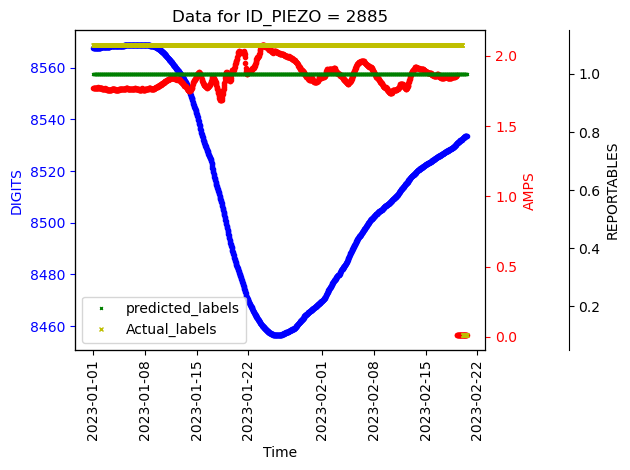

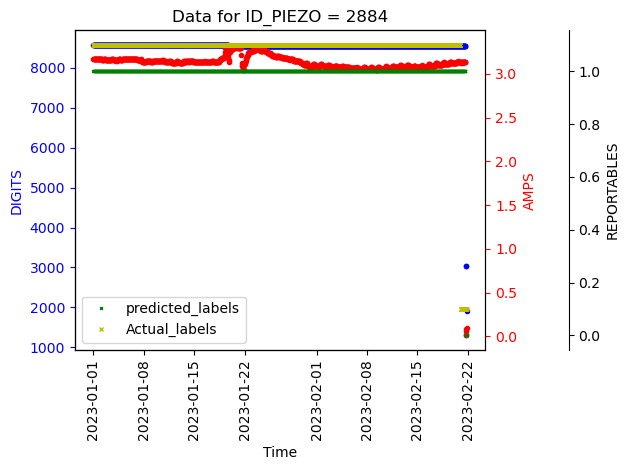

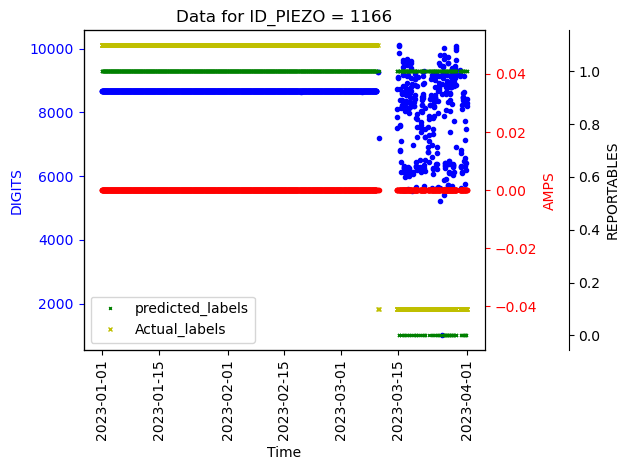

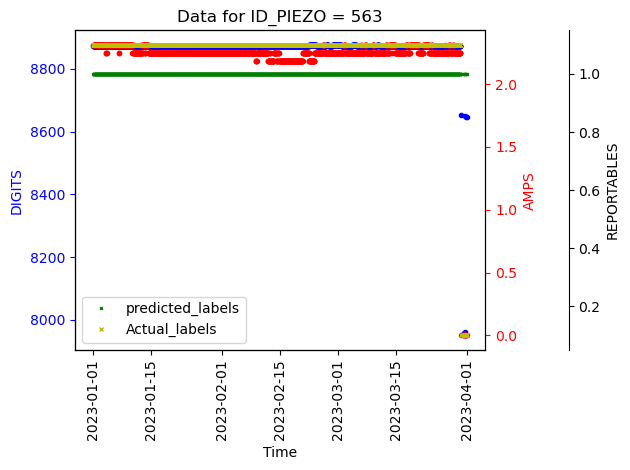

In [22]:
import matplotlib.pyplot as plt

val['REPORTABLE']=val['REPORTABLE']+0.1

# Filter the dataframe

filtered_df = val[val['COMPARE'] == False]

 

# Get the unique 'ID_PIEZO' values

unique_ids = filtered_df['ID_PIEZO'].unique()



# Plot data for each unique 'ID_PIEZO'

for id in unique_ids:

    # Filter dataframe for the current 'ID_PIEZO'

    df_id = val[val['ID_PIEZO'] == id]
 

    # Create a new figure and two subplots, sharing x-axis

    fig, ax1 = plt.subplots()

 

    # First subplot for 'X' values

    ax1.plot(df_id['TM_STAMP'], df_id['DIGITS'], 'bo', markersize=3)

    ax1.set_xlabel('Time')
    plt.xticks(rotation=90)

    # Make the y-axis label and line color blue to match the line color.

    ax1.set_ylabel('DIGITS', color='b')

    ax1.tick_params('y', colors='b')

 
    # Second subplot for 'Y' values, sharing the same x-axis

    ax2 = ax1.twinx()

    ax2.plot(df_id['TM_STAMP'], df_id['AMP'], 'ro', markersize=3)

    # Make the y-axis label and line color red to match the line color.

    ax2.set_ylabel('AMPS', color='r')

    ax2.tick_params('y', colors='r')
    
    # Create a third axis sharing the same x-axis
    ax3 = ax1.twinx()

    # Offset the third axis
    ax3.spines['right'].set_position(('outward', 60))

    # Plot data on the third axis
    ax3.plot(df_id['TM_STAMP'],df_id['PREDICTIONS'],'gx', markersize=2, label='predicted_labels')
    ax3.plot(df_id['TM_STAMP'],df_id['REPORTABLE'],'yx', markersize=3, label='Actual_labels')
    ax3.set_ylabel('REPORTABLES', color='black')
    ax3.tick_params('y', colors='black')
    
    # Add a legend
    lines = ax3.get_lines()
    ax3.legend(lines, [line.get_label() for line in lines])
    # Add a title to the plot

    plt.title(f"Data for ID_PIEZO = {id}")


    fig.tight_layout()  # This ensures the right y-label is not cut off
    


    plt.show()
    #
    fig.savefig('C:\Temp\ML_FIGURES_check7\{0}.png'.format(id), bbox_inches='tight',dpi=300)